# Part I: modeling the housing price

In [56]:
import pandas as pd
import numpy as np 
from scipy import stats
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
import random
import copy

# Prepping the Data

In [57]:
df = pd.read_csv("data_CASE_group_18.csv")

print (df.shape)

(2467, 39)


In [58]:
print(df.describe()) 

              Price         Area  No. of Bedrooms       Resale  \
count  2.467000e+03  2467.000000      2467.000000  2467.000000   
mean   9.803732e+06  1643.473044         2.625861     0.226996   
std    8.680468e+06   730.814725         0.679819     0.418975   
min    2.000000e+06   500.000000         1.000000     0.000000   
25%    4.760000e+06  1163.000000         2.000000     0.000000   
50%    7.800000e+06  1500.000000         3.000000     0.000000   
75%    1.090000e+07  1830.000000         3.000000     0.000000   
max    1.650000e+08  8500.000000         8.000000     1.000000   

       MaintenanceStaff    Gymnasium  SwimmingPool  LandscapedGardens  \
count       2467.000000  2467.000000   2467.000000        2467.000000   
mean           0.419133     0.746251      0.715444           0.624645   
std            1.641985     1.625421      1.629792           1.639242   
min            0.000000     0.000000      0.000000           0.000000   
25%            0.000000     0.000000    

Observe that some of the binary data has 9 as the max value

In [59]:
# We see that the data contains 0,1,9 

df['MaintenanceStaff'].unique()

# We can infer that the 9 in this instance is missing data 
cols = df.columns[4:39]
df[cols] = df[cols].astype(float).replace(9, np.nan)


# We see that all the binary variables have the same amount of missing variable, so we check that the same rows are missing every column 

is_missing = df[cols].isna()
missing_per_row = is_missing.sum(axis=1)
print(missing_per_row.value_counts().sort_index())

is_missing.all(axis=1).sum()   # rows missing in every column
is_missing.any(axis=1).sum()   # rows missing in at least one column

# Ok We confirmed that the missing data is pretty much all or nothing, before dropping this data it is important to check if the data is statistically different

df['all_missing'] = df[cols].isna().all(axis=1)

vars_ = ['Price', 'Area', 'No. of Bedrooms']

comparison = df.groupby('all_missing')[vars_].mean().T
comparison.columns = ['Complete', 'Missing']          # False -> Complete, True -> Missing
comparison['Difference'] = comparison['Missing'] - comparison['Complete']

comparison['% Diff'] = 100 * comparison['Difference'] / comparison['Complete']

pooled_sd = df[vars_].std()
comparison['Std Diff'] = comparison['Difference'] / pooled_sd

print(comparison.round(2))

# Now there is sufficient support for dropping it 
df['all_missing'] = df[cols].isna().all(axis=1)
df_clean = df.loc[~df['all_missing']].drop(columns='all_missing')
print(df_clean.shape)

0     2383
35      84
Name: count, dtype: int64


/tmp/ipykernel_2526/2363833836.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df[cols] = df[cols].astype(float).replace(9, np.nan)


                   Complete     Missing  Difference  % Diff  Std Diff
Price            9830328.97  9049202.35  -781126.62   -7.95     -0.09
Area                1643.01     1656.73       13.72    0.84      0.02
No. of Bedrooms        2.63        2.55       -0.08   -3.08     -0.12
(2383, 39)


/tmp/ipykernel_2526/2363833836.py:27: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  comparison['Difference'] = comparison['Missing'] - comparison['Complete']
/tmp/ipykernel_2526/2363833836.py:29: FutureWarning: ChainedAssignmentError: behavi

In [60]:
# We also remove duplicates 
df_clean = df_clean.drop_duplicates()
print(df_clean.shape)

#outlier alone
df_clean = df_clean[df_clean['Price'] < 165000000]
print(df_clean.shape,df_clean.describe())

(1844, 39)
(1843, 39)               Price         Area  No. of Bedrooms       Resale  \
count  1.843000e+03  1843.000000      1843.000000  1843.000000   
mean   1.018557e+07  1679.073250         2.654910     0.259902   
std    8.578173e+06   767.927228         0.686667     0.438700   
min    2.000000e+06   500.000000         1.000000     0.000000   
25%    4.958000e+06  1183.000000         2.000000     0.000000   
50%    7.998000e+06  1510.000000         3.000000     0.000000   
75%    1.120000e+07  1878.500000         3.000000     1.000000   
max    6.640000e+07  8500.000000         8.000000     1.000000   

       MaintenanceStaff    Gymnasium  SwimmingPool  LandscapedGardens  \
count       1843.000000  1843.000000   1843.000000        1843.000000   
mean           0.113945     0.474769      0.444384           0.355399   
std            0.317830     0.499499      0.497032           0.478764   
min            0.000000     0.000000      0.000000           0.000000   
25%            0.0

# Summary Statistics 

              Price         Area  No. of Bedrooms  ShoppingMall       School
count  1.843000e+03  1843.000000      1843.000000   1843.000000  1843.000000
mean   1.018557e+07  1679.073250         2.654910      0.072165     0.041237
std    8.578173e+06   767.927228         0.686667      0.258831     0.198892
min    2.000000e+06   500.000000         1.000000      0.000000     0.000000
25%    4.958000e+06  1183.000000         2.000000      0.000000     0.000000
50%    7.998000e+06  1510.000000         3.000000      0.000000     0.000000
75%    1.120000e+07  1878.500000         3.000000      0.000000     0.000000
max    6.640000e+07  8500.000000         8.000000      1.000000     1.000000


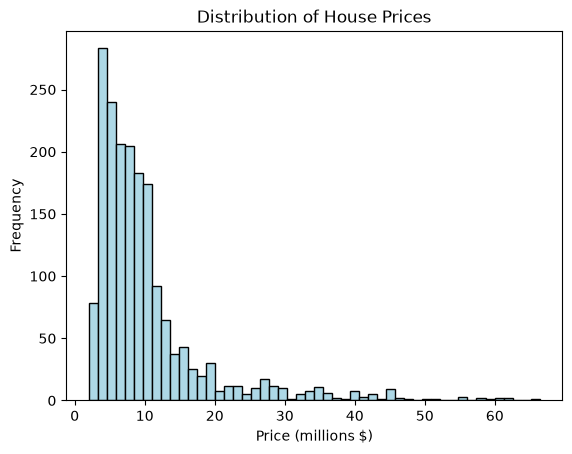

In [61]:
statistics = df_clean[['Price','Area','No. of Bedrooms','ShoppingMall','School']].describe()
print(statistics)

plt.hist(df_clean['Price']/ 1000000, bins=50, histtype = "bar", edgecolor = "black", color = "lightblue")
plt.xlabel("Price (millions $)")
plt.ylabel("Frequency")
plt.title("Distribution of House Prices")
plt.show()



In [62]:
# The data appears to be very right skewed. 

# To verify this we now test for normality
price = df_clean['Price']

# Skewness and kurtosis checks 
print('Skew:', stats.skew(price))
print('Excess kurtosis:', stats.kurtosis(price))

# For the test of normality, we choose the Jarque-Bera Test. 
# We chose this test as it is an asymptotic goodness of fit test.
# Making it appropriate considering the skewed histogram and sufficient sample size (n=1844)


#H0: Prices follow a normal Distribution 
#H1: The prices do not follow a normal distrubtion 

print(stats.jarque_bera(price))

# test statistic = 9315.39
# p-value ≈ 0.0, the null hypothesis is rejected. 

Skew: 2.7783245321932535
Excess kurtosis: 9.509524545465892
SignificanceResult(statistic=np.float64(9315.397878498234), pvalue=np.float64(0.0))


 $H0$: The data is normally distributed, with skewness=0 and kurtosis=3\
 $H1$: The data is normally distributed, with skewness≠0, kurtosis≠3 or both

$$JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right)$$

Results:<br> 
$JB = 9315.39$\
$JB> \chi^2_{0.95}(2) = 5.991$\
$p$ ≈ 0.00

This verifies that the data is non normal. It is  right-skewed with heavy fails. 

In [63]:
# Here we choose 2 random variables along with Area 
cols = df_clean.columns[2:39]
random_cols = df_clean[cols].sample(n=2, axis=1, random_state=42)
print(random_cols.columns.tolist())


cols = ['Price', 'Area', 'CarParking', 'ClubHouse']
stats_order = ['mean', 'std', 'min', 'median', 'max']

# Summary statistics: one row per variable
s = df_clean[cols].agg(['count'] + stats_order).T

# Decimal places per variable
decimals = {'Price': 0, 'Area': 1, 'CarParking': 3, 'ClubHouse': 3}

rows = []
for v in cols:
    d = decimals[v]
    r = s.loc[v]
    cells = [f"{int(r['count']):,}"] + [f"{r[k]:,.{d}f}" for k in stats_order]
    rows.append(v + " & " + " & ".join(cells) + r" \\")
rows_tex = "\n".join(rows)

latex = r"""\begin{table}[p]
\centering
\caption{Summary Statistics}
\vspace{6pt}
\begin{tabular}{lrrrrrr}
\toprule
Variable & N & Mean & SD & Min & Median & Max \\
\midrule
%%ROWS%%
\bottomrule
\end{tabular}
\end{table}
""".replace("%%ROWS%%", rows_tex)

with open("table1.tex", "w") as f:
    f.write(latex)

print(latex)

['CarParking', 'ClubHouse']
\begin{table}[p]
\centering
\caption{Summary Statistics}
\vspace{6pt}
\begin{tabular}{lrrrrrr}
\toprule
Variable & N & Mean & SD & Min & Median & Max \\
\midrule
Price & 1,843 & 10,185,573 & 8,578,173 & 2,000,000 & 7,998,000 & 66,400,000 \\
Area & 1,843 & 1,679.1 & 767.9 & 500.0 & 1,510.0 & 8,500.0 \\
CarParking & 1,843 & 0.476 & 0.500 & 0.000 & 0.000 & 1.000 \\
ClubHouse & 1,843 & 0.436 & 0.496 & 0.000 & 0.000 & 1.000 \\
\bottomrule
\end{tabular}
\end{table}



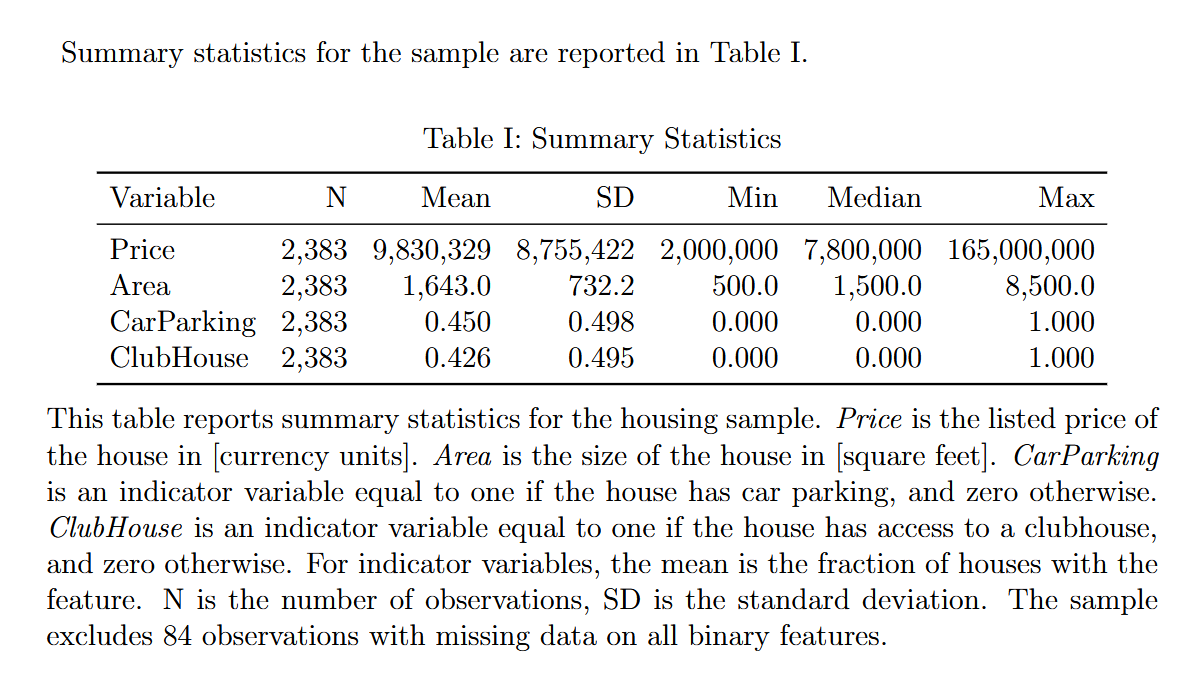

# Interpretation


The summary statistics show that the average house price is around 9.8 million, with an average area of 1.600 square units. The average value of CarParking, and ClubHouse, show that rougly half of the houses have a carpark or club house. 

In [85]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline


In [65]:
Y = df_clean['Price']
X = df_clean['Area']

In [66]:
print(df.index[df["Price"] == 165000000])
#Looks like we have 1 serious outlier here 
outlier = df.index[df["Price"] == 165000000]

# This appears to be a measurement error, but to be cautious we will not remove it immediately 
# Instead we divide by 10 and assign it to a seperate dataframe
df_out = df_clean.copy() 
df_out.loc[df_out["Price"] == 165000000, "Price"] /= 10 


Index([1354], dtype='int64')


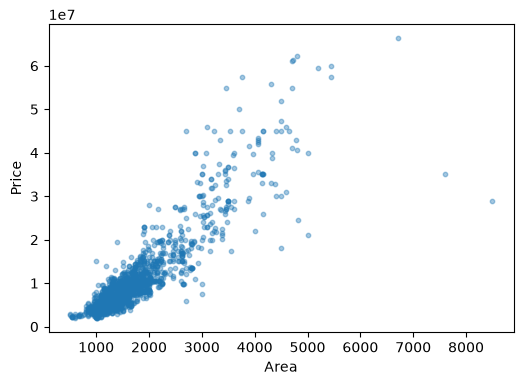

In [67]:
plt.figure(figsize=(6, 4))
plt.scatter(df_out["Area"], df_out["Price"], alpha=0.4, s=10)
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

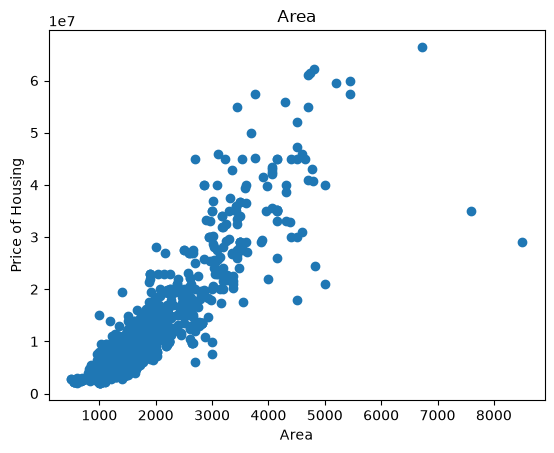

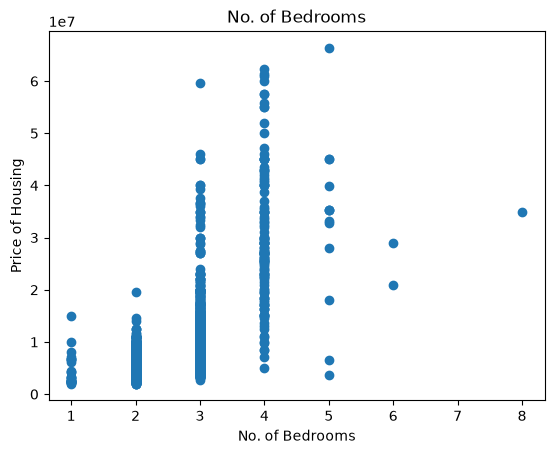

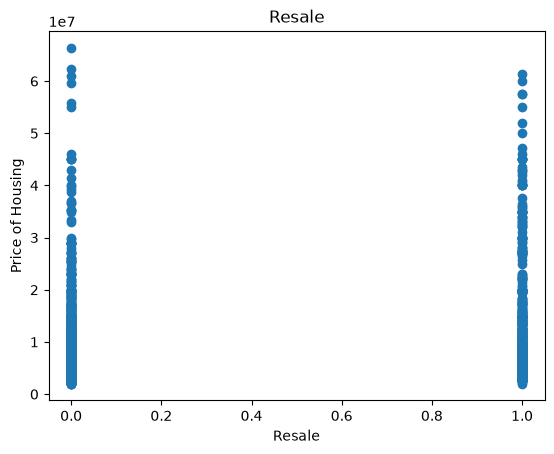

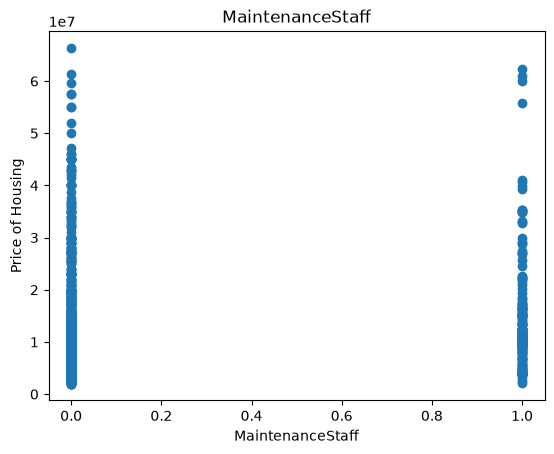

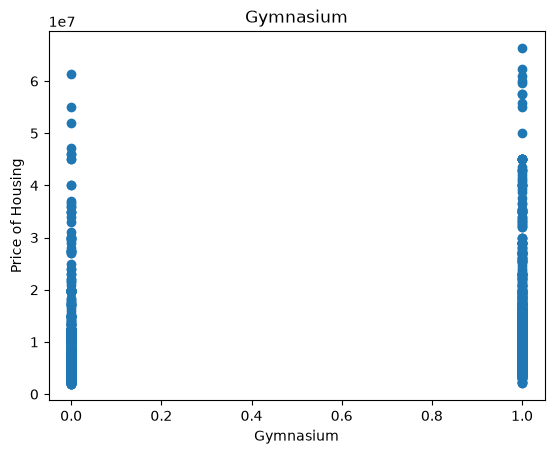

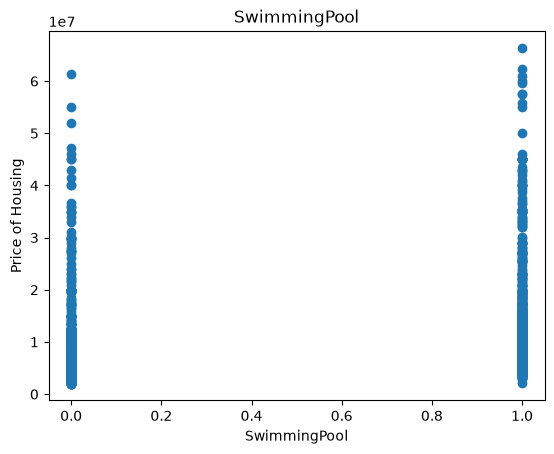

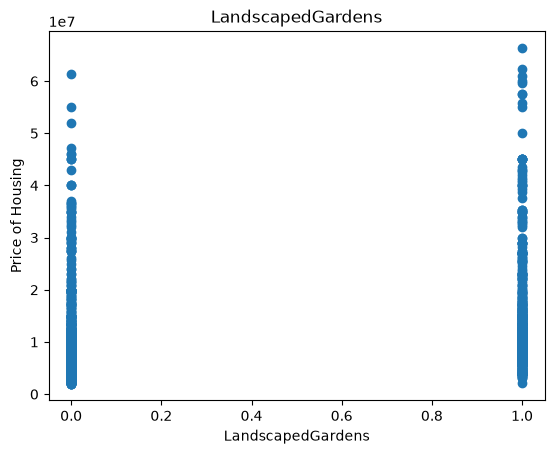

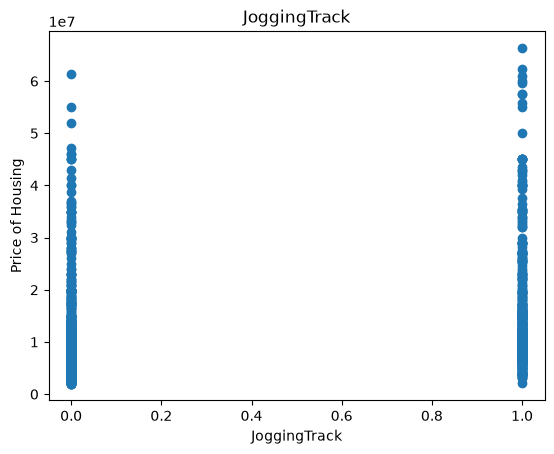

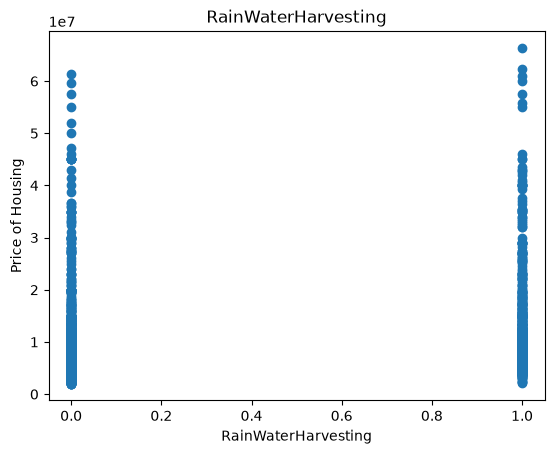

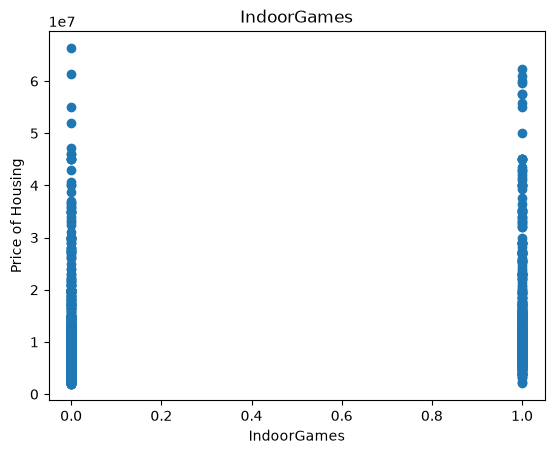

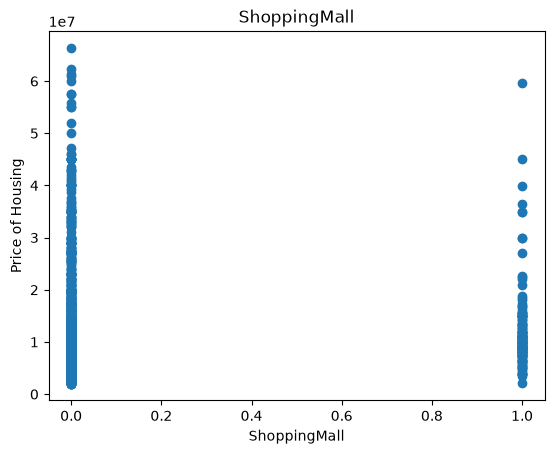

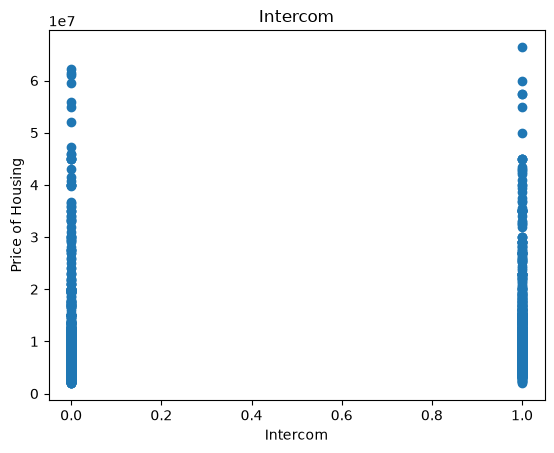

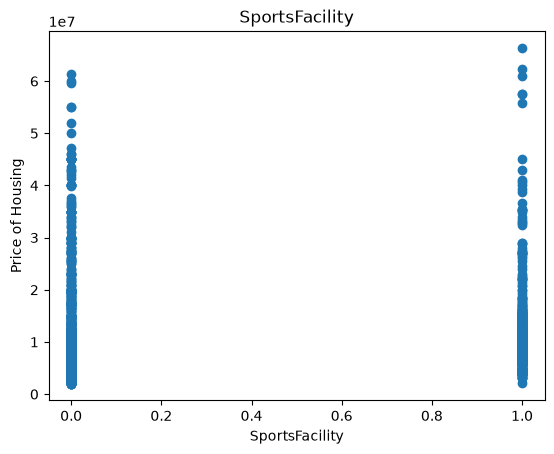

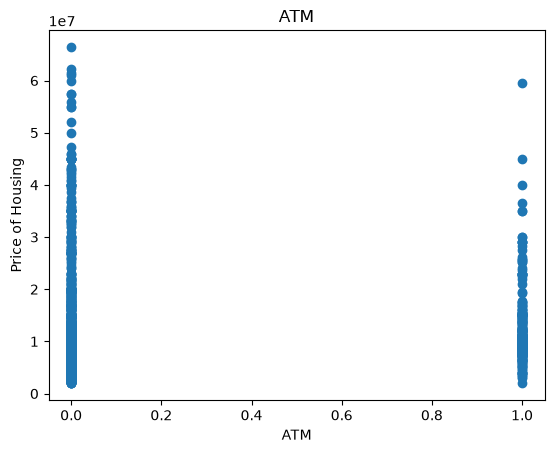

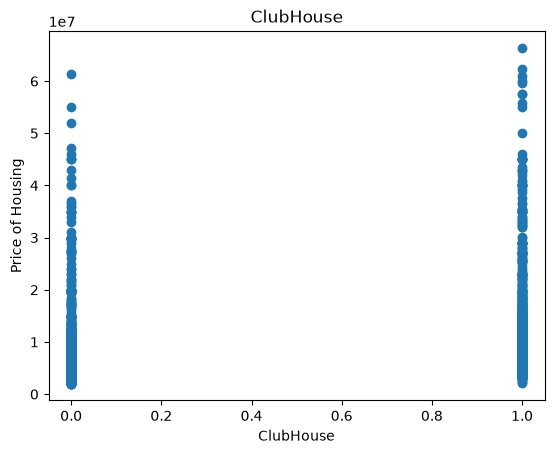

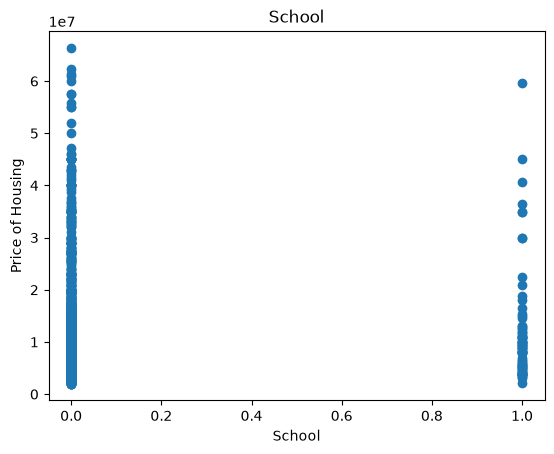

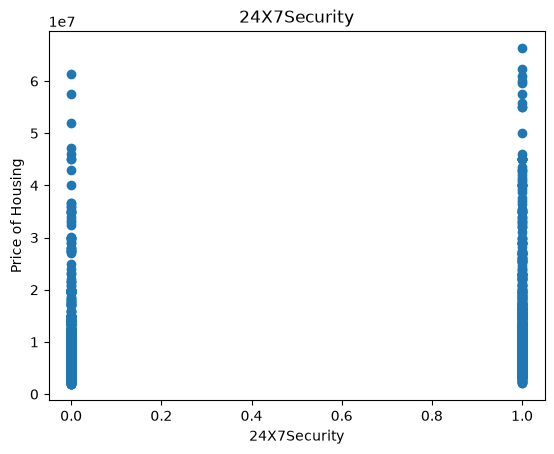

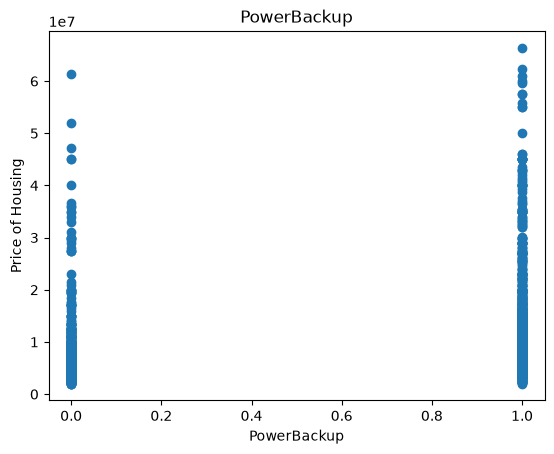

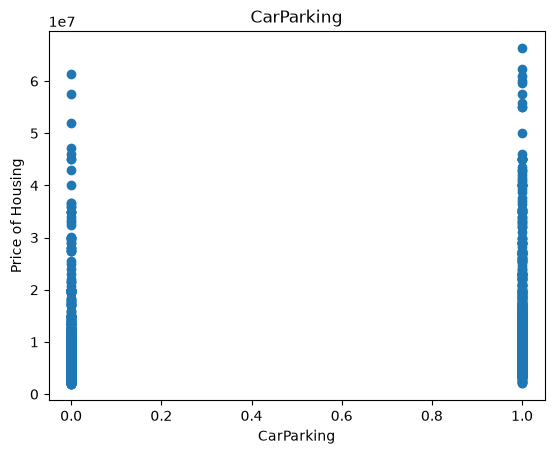

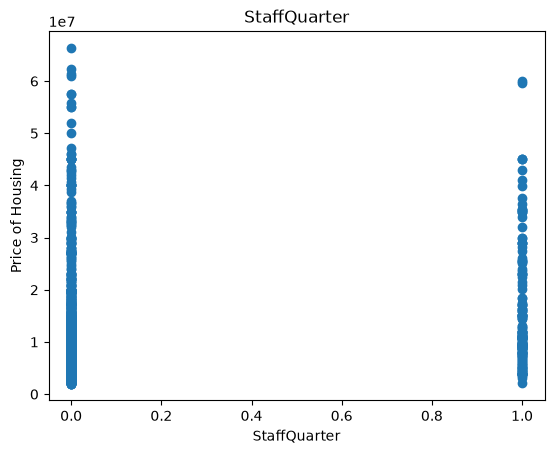

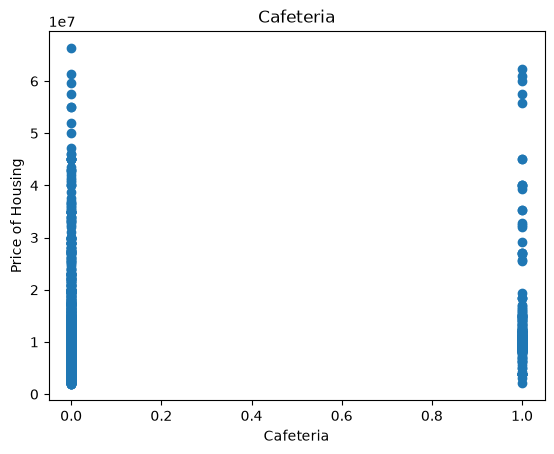

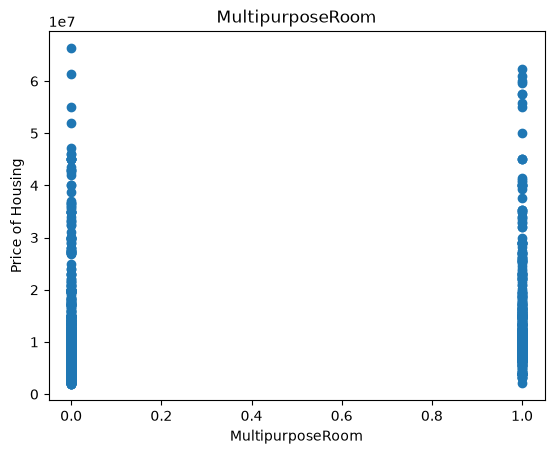

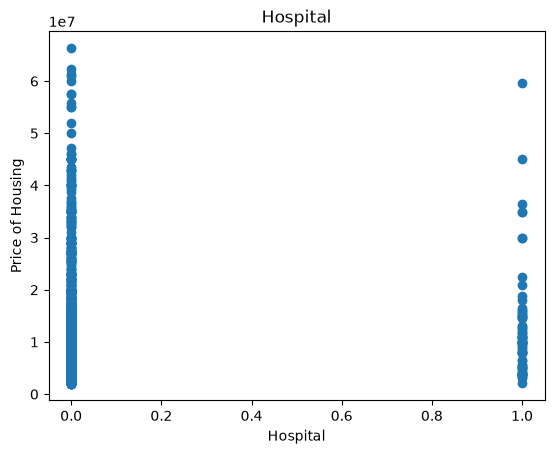

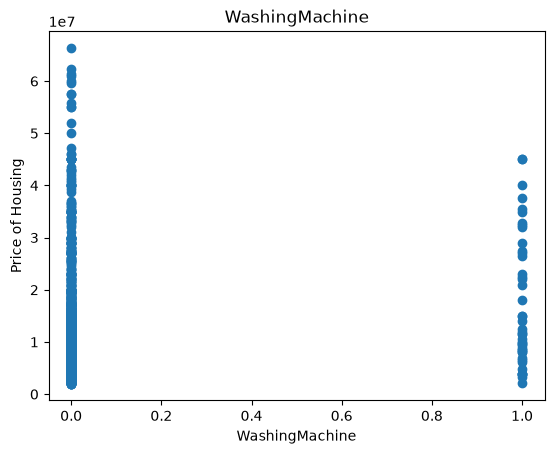

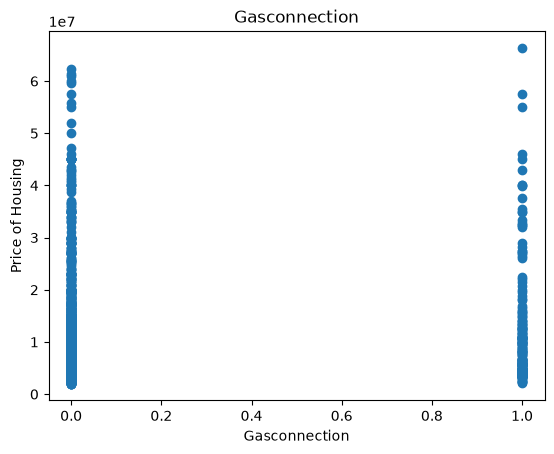

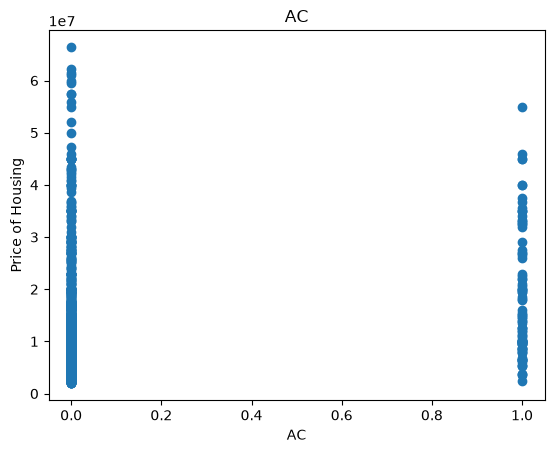

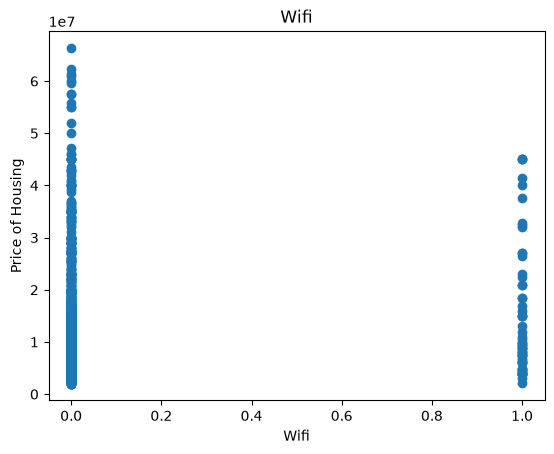

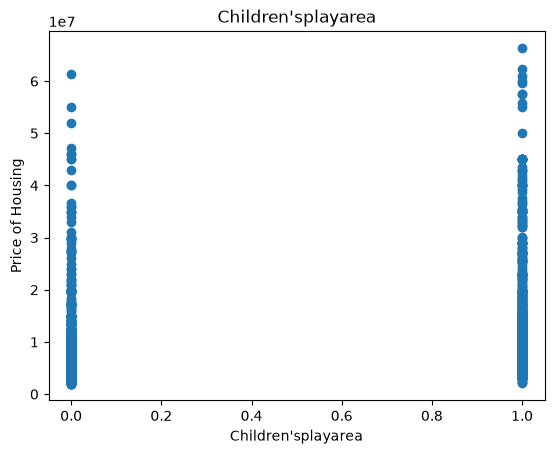

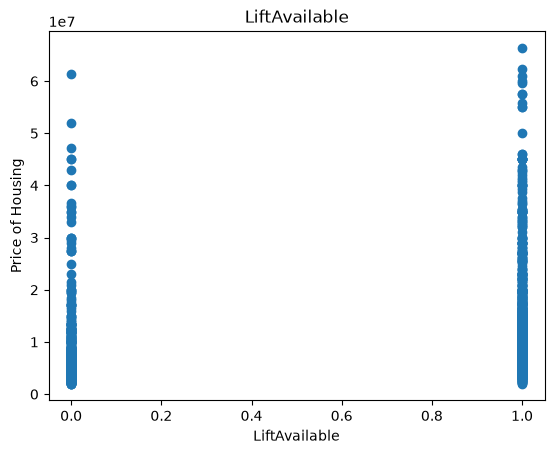

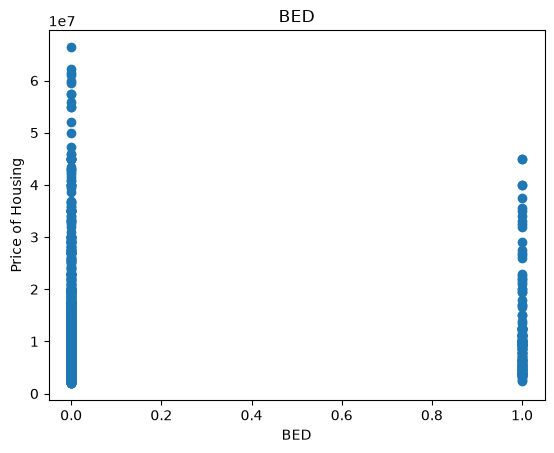

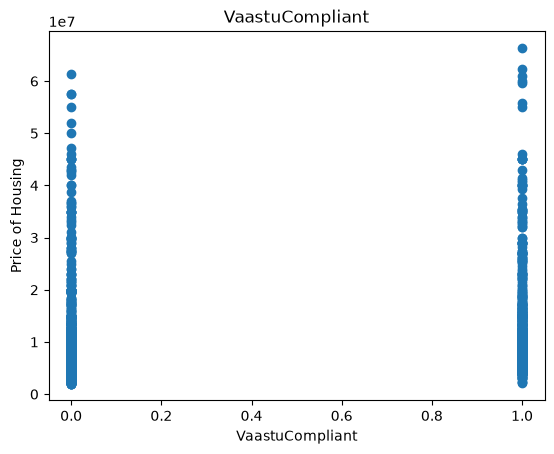

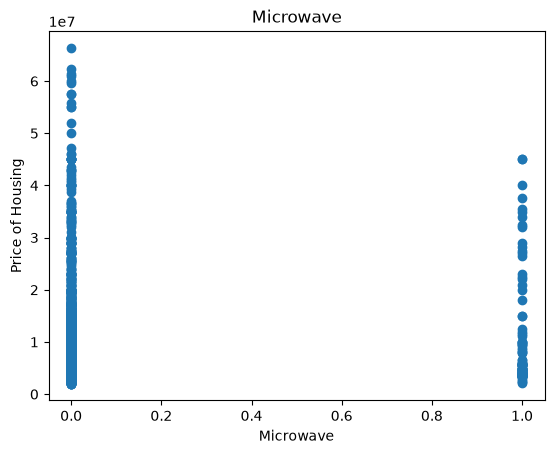

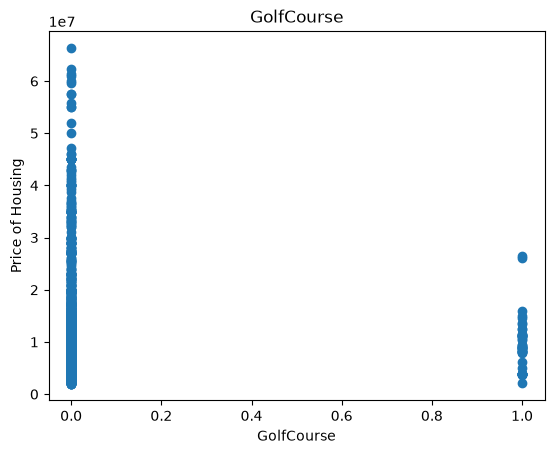

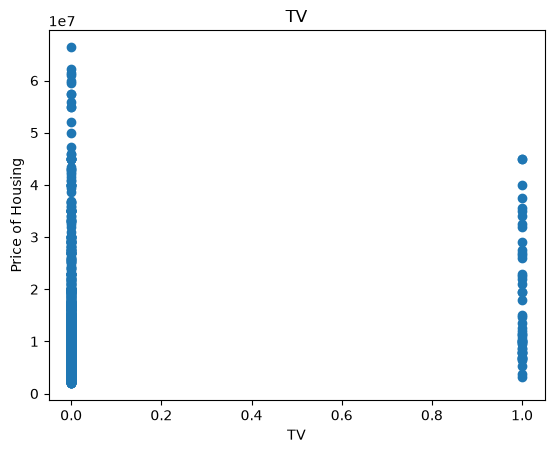

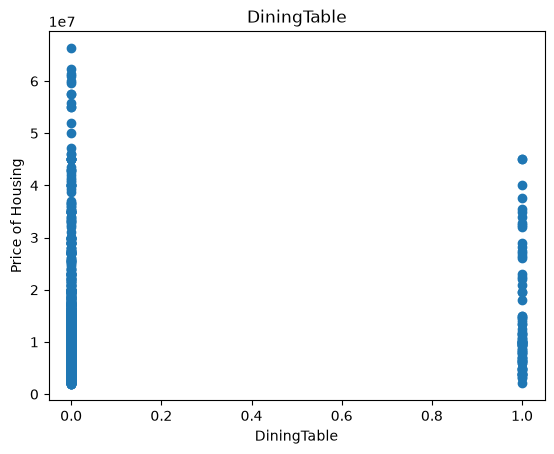

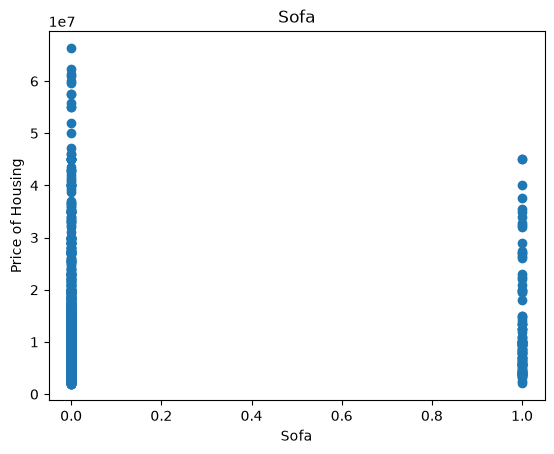

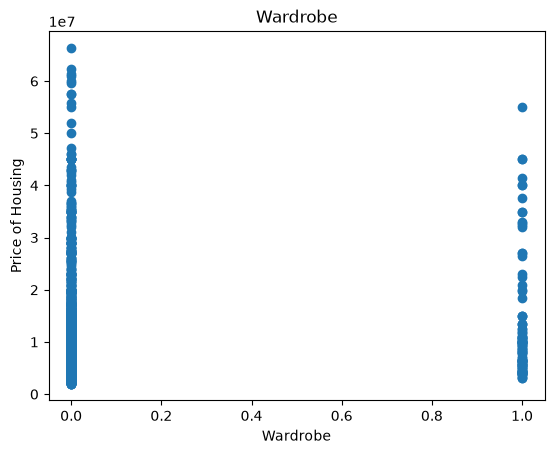

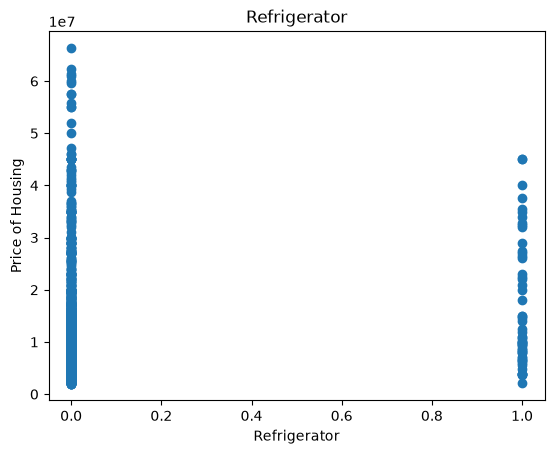

In [68]:
for label in df_clean.columns[1:]:
    plt.scatter(df_clean[label],df_clean['Price'])
    plt.title(label)
    plt.ylabel("Price of Housing")
    plt.xlabel(label)
    plt.show()

## Training and predicting 

The company allows you to use 3 different models for the housing price:

- Model 1: A multivariate linear regression using all features (benchmark)
- Model 2: Model 1 plus Lasso 
- Model 3: Model 1 plus Ridge

Use a 60/20/20 rule for the training/validation/testing set (set the state fixed). Models 2 - 3 contain **hyperparameters** which you need to tune. In general, do **NOT** use any cross-validation techniques. Instead do the following for Model 2 and 3: Make a vector of different values of the hyperparameter; then create a loop and estimate the ML models using the correct data. Make and show a plot of an appropriate loss function against the different values of the hyperparameter. 

**Important:** Make sure that your features are standardized!

## Deliverables
- Make Table 2 with parameter estimation results of Model 1. Report the constant, the first 5 coefficients (with their standard errors) and the R-squared. Interpret the coefficients related to *Area* and *MaintenanceStaff*. 
- An explanation, accompanied by tables or figures about the hyperparameters you will use for Model 2 and 3. 
- Table 3 with MAPE and MSPE of the predicted housing prices in the testing set.
- Take the best model and test whether the squared prediction errors are statistically different from the benchmark model (by the Diebold Mariano test). What is your conclusion?


# Model 1: Linear Regression

In [113]:
def data_prep(data,label,seed=42, scale=True):
    # Setting the X and Y variables
    y = data['Price']
    X = data.drop(columns=['Price']).astype(float)

    # Splitting the Training, Validation, and Testing Data
    X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, random_state=seed)
    X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=seed)
    print(f"[{label}] split sizes:", len(X_train), len(X_val), len(X_test))

    # Applying the Scaler (fit on train only)
    if scale: 
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_val = scaler.transform(X_val)
        X_test = scaler.transform(X_test)

    return X_train, X_val, X_test, y_train, y_val, y_test

X_clean = data_prep(df_clean, "Original",seed=42)



[Original] split sizes: 1105 369 369


In [114]:
# We create a function that runs the linear regression fit from sklearn and outputs a table with the first 5 coefficients 
def run_linreg(prepared, label, feature_names, n_coefs=5):
    X_train, X_val, X_test, y_train, y_val, y_test = prepared
    X_train = np.asarray(X_train, dtype=float)
    X_val   = np.asarray(X_val, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    y_val   = np.asarray(y_val, dtype=float)

    # Estimate the linear regression function with sklearn
    linreg = LinearRegression().fit(X_train, y_train)
    val_pred = linreg.predict(X_val)

    # As robust SEs will converge for homoskedastic errors
    # We choose to calculate the HC3 standard error Variant 
    n, k = X_train.shape
    X_design = np.column_stack([np.ones(n), X_train])      
    resid = y_train - linreg.predict(X_train)
    XtX_inv = np.linalg.pinv(X_design.T @ X_design)

    # We use the following formula for the 
    # "Sandwhich" estimator HC3: (X'X)^-1 X' diag(e^2 / (1-h)^2) X (X'X)^-1
    h = np.einsum("ij,jk,ik->i", X_design, XtX_inv, X_design)
    h = np.clip(h, 0, 1 - 1e-12)                                
    w = resid**2 / (1 - h)**2
    cov = XtX_inv @ (X_design.T * w) @ X_design @ XtX_inv
    se = np.sqrt(np.diag(cov))

    #Outputting the table 
    coef_table = pd.DataFrame(
        {"coef": np.r_[linreg.intercept_, linreg.coef_], "std_err": se},
        index=["const"] + list(feature_names),
    ).head(n_coefs + 1)

    results = {
        "train_r2": linreg.score(X_train, y_train),
        "val_mse": mean_squared_error(y_val, val_pred),
        "val_mae": mean_absolute_error(y_val, val_pred),
        "val_r2": linreg.score(X_val, y_val),
    }

    print(f"[{label}] constant and first {n_coefs} coefficients:")
    print(coef_table.round(4).to_string())
    print(f"[{label}] training R²:    {results['train_r2']:.4f}")
    print(f"[{label}] validation MSE: {results['val_mse']:.4f}")
    print(f"[{label}] validation MAE: {results['val_mae']:.4f}")
    print(f"[{label}] validation R²:  {results['val_r2']:.4f}\n")

    results["coef_table"] = coef_table
    results["model"] = linreg
    return results




In [115]:
# Calculating the first 5 coefficients for the base case 
res_clean = run_linreg(X_clean, "df_clean", df_clean.drop(columns=["Price"]).columns)

latex = res_clean["coef_table"].round(2).to_latex(
    float_format="{:,.2f}".format,
    caption="Linear regression results for df\\_out",
    label="tab:linreg_out",
)
print(latex)

[df_clean] constant and first 5 coefficients:
                          coef      std_err
const             9.998051e+06  110181.5043
Area              7.949010e+06  401441.2444
No. of Bedrooms  -1.077603e+06  272569.0100
Resale            5.499945e+05  150376.7554
MaintenanceStaff -3.749063e+05  157101.8725
Gymnasium        -5.496697e+05  340565.4761
[df_clean] training R²:    0.8218
[df_clean] validation MSE: 12130481031219.9785
[df_clean] validation MAE: 2194891.0070
[df_clean] validation R²:  0.8319

\begin{table}
\caption{Linear regression results for df\_out}
\label{tab:linreg_out}
\begin{tabular}{lrr}
\toprule
 & coef & std_err \\
\midrule
const & 9,998,050.65 & 110,181.50 \\
Area & 7,949,010.11 & 401,441.24 \\
No. of Bedrooms & -1,077,602.64 & 272,569.01 \\
Resale & 549,994.53 & 150,376.76 \\
MaintenanceStaff & -374,906.29 & 157,101.87 \\
Gymnasium & -549,669.70 & 340,565.48 \\
\bottomrule
\end{tabular}
\end{table}



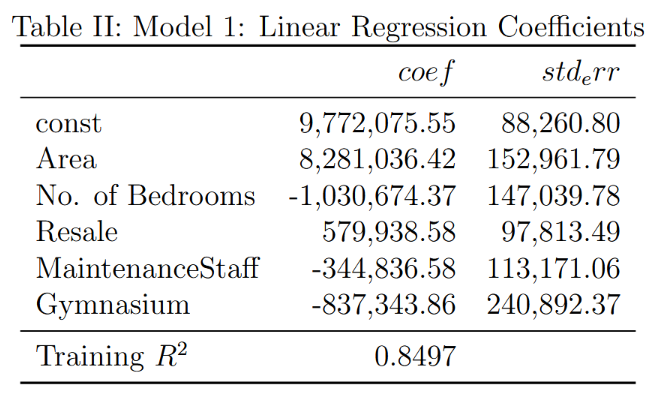


# Interpretation 

The predicted multivariate regression shows that the predicted base price of a house is around 9.77 million dollars. The area increases the price by 8.2 million per. Each additional bedroom reduces the predicted price by 1.03 million. If the house has been resold, the value increases by around 580 thousand. The presence of Maintenence staff reduces the property price by 340 thousand. I predict that this is because 

# Model 2 Lasso

In [145]:
def run_lasso(prepared, label, feature_names=None, n_alphas=50, decades=4, max_iter=50000, seed=None):
    # We repeat the step of turning the data into arrays 
    X_train, X_val, X_test, y_train, y_val, y_test = prepared
    X_train, X_val, X_test = (np.asarray(a, dtype=float) for a in (X_train, X_val, X_test))
    y_train, y_val, y_test = (np.asarray(a, dtype=float) for a in (y_train, y_val, y_test))
    n, k = X_train.shape
    # We 
    if feature_names is not None:
        assert len(feature_names) == k, "feature_names must match the number of columns"
    if seed is not None:
        random.seed(seed)

    # Here we centre the data 
    Xc = X_train - X_train.mean(axis=0)
    # alpha_max: smallest alpha at which all coefficients are zero
    alpha_max = np.max(np.abs(Xc.T @ (y_train - y_train.mean()))) / n
    log_hi, log_lo = np.log10(alpha_max), np.log10(alpha_max) - decades

    # Step 1 is estimating the Lasso regression on the training data with a random alpha 
    random_alpha = 10 ** random.uniform(log_lo, log_hi)
    init_model = Lasso(alpha=random_alpha, max_iter=max_iter).fit(X_train, y_train)
    init_val_mse = mean_squared_error(y_val, init_model.predict(X_val))
    print(f"[{label}] random alpha: {random_alpha:.4g} -> validation MSE: {init_val_mse:.4f}")

    # Step 2: optimise alpha on the validation data (models are fitted on training data only)
    alphas = np.logspace(log_lo, log_hi, n_alphas)
    train_mses, val_mses = [], []
    for a in alphas:
        m = Lasso(alpha=a, max_iter=max_iter).fit(X_train, y_train)
        train_mses.append(mean_squared_error(y_train, m.predict(X_train)))
        val_mses.append(mean_squared_error(y_val, m.predict(X_val)))
    best_idx = int(np.argmin(val_mses))
    best_alpha = alphas[best_idx]
    if best_idx == 0:
        print(f"[{label}] WARNING: best alpha is at the small end of the grid, consider increasing `decades`.")
    elif best_idx == n_alphas - 1:
        print(f"[{label}] NOTE: best alpha is alpha_max, so lasso does not beat the intercept-only model.")

    # Step 3: refit at the best alpha and evaluate once on the test data
    best_model = Lasso(alpha=best_alpha, max_iter=max_iter).fit(X_train, y_train)
    test_pred = best_model.predict(X_test)
    test_mse = mean_squared_error(y_test, test_pred)
    test_mae = mean_absolute_error(y_test, test_pred)
    test_r2 = r2_score(y_test, test_pred)
    n_nonzero = int(np.sum(best_model.coef_ != 0))

    results = {
        "alpha": best_alpha,
        "n_nonzero": n_nonzero,
        "test_mse": test_mse,
        "test_mae": test_mae,
        "test_r2": test_r2,
        "coef": pd.Series(best_model.coef_,
                          index=list(feature_names) if feature_names is not None else None),
    }

    # Plot: training and validation MSE against alpha
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(alphas, train_mses, marker="o", ms=3, label="Training MSE")
    ax.plot(alphas, val_mses, marker="o", ms=3, label="Validation MSE")
    ax.axvline(best_alpha, color="grey", linestyle="--", label=f"Best alpha = {best_alpha:.3g}")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("MSE")
    ax.set_title(f"Lasso: loss vs alpha [{label}]")
    ax.legend()
    ax.grid(True, alpha=0.3)

    print(f"[{label}] best alpha:             {best_alpha:.4g}")
    print(f"[{label}] non-zero coefficients:  {n_nonzero} of {k}")
    print(f"[{label}] test MSE:               {test_mse:.4f}")
    print(f"[{label}] test MAE:               {test_mae:.4f}")
    print(f"[{label}] test R²:                {test_r2:.4f}\n")

    if feature_names is not None:
        coefs = results["coef"]
        nz = coefs[coefs != 0]
        print(f"[{label}] non-zero coefficients (sorted by absolute size):")
        print(nz.reindex(nz.abs().sort_values(ascending=False).index).to_string(), "\n")

    return results, best_model, pd.DataFrame({"alpha": alphas, "train_mse": train_mses, "val_mse": val_mses})

# Model 3 Ridge 

In [148]:
def run_ridge(prepared, label, feature_names=None, n_alphas=50, decades=1000, max_iter=50000, seed=None):
    # We repeat the step of turning the data into arrays 
    X_train, X_val, X_test, y_train, y_val, y_test = prepared
    X_train, X_val, X_test = (np.asarray(a, dtype=float) for a in (X_train, X_val, X_test))
    y_train, y_val, y_test = (np.asarray(a, dtype=float) for a in (y_train, y_val, y_test))
    n, k = X_train.shape
    # We 
    if feature_names is not None:
        assert len(feature_names) == k, "feature_names must match the number of columns"
    if seed is not None:
        random.seed(seed)

    # Here we centre the data 
    Xc = X_train - X_train.mean(axis=0)
    # alpha_max: smallest alpha at which all coefficients are zero
    alpha_max = np.max(np.abs(Xc.T @ (y_train - y_train.mean()))) / n
    log_hi, log_lo = np.log10(alpha_max), np.log10(alpha_max) - decades

    # Step 1 is estimating the Ridge regression on the training data with a random alpha 
    random_alpha = 10 ** random.uniform(log_lo, log_hi)
    init_model = Ridge(alpha=random_alpha, max_iter=max_iter).fit(X_train, y_train)
    init_val_mse = mean_squared_error(y_val, init_model.predict(X_val))
    print(f"[{label}] random alpha: {random_alpha:.4g} -> validation MSE: {init_val_mse:.4f}")

    # Step 2: optimise alpha on the validation data (models are fitted on training data only)
    alphas = np.logspace(log_lo, log_hi, n_alphas)
    train_mses, val_mses = [], []
    for a in alphas:
        m = Ridge(alpha=a, max_iter=max_iter).fit(X_train, y_train)
        train_mses.append(mean_squared_error(y_train, m.predict(X_train)))
        val_mses.append(mean_squared_error(y_val, m.predict(X_val)))
    best_idx = int(np.argmin(val_mses))
    best_alpha = alphas[best_idx]
    if best_idx == 0:
        print(f"[{label}] WARNING: best alpha is at the small end of the grid, consider increasing `decades`.")
    elif best_idx == n_alphas - 1:
        print(f"[{label}] NOTE: best alpha is alpha_max, so lasso does not beat the intercept-only model.")

    # Step 3: refit at the best alpha and evaluate once on the test data
    best_model = Ridge(alpha=best_alpha, max_iter=max_iter).fit(X_train, y_train)
    test_pred = best_model.predict(X_test)
    test_mse = mean_squared_error(y_test, test_pred)
    test_mae = mean_absolute_error(y_test, test_pred)
    test_r2 = r2_score(y_test, test_pred)
    n_nonzero = int(np.sum(best_model.coef_ != 0))
    
    results = {
        "alpha": best_alpha,
        "n_nonzero": n_nonzero,
        "test_mse": test_mse,
        "test_mae": test_mae,
        "test_r2": test_r2,
        "coef": pd.Series(best_model.coef_,
                          index=list(feature_names) if feature_names is not None else None),
    }

    # Plot: training and validation MSE against alpha
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(alphas, train_mses, marker="o", ms=3, label="Training MSE")
    ax.plot(alphas, val_mses, marker="o", ms=3, label="Validation MSE")
    ax.axvline(best_alpha, color="grey", linestyle="--", label=f"Best alpha = {best_alpha:.3g}")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("MSE")
    ax.set_title(f"Ridge: loss vs alpha [{label}]")
    ax.legend()
    ax.grid(True, alpha=0.3)

    print(f"[{label}] best alpha (Ridge):             {best_alpha:.4g}")
    print(f"[{label}] non-zero coefficients (Ridge):  {n_nonzero} of {k}")
    print(f"[{label}] test MSE (Ridge):               {test_mse:.4f}")
    print(f"[{label}] test MAE (Ridge):               {test_mae:.4f}")
    print(f"[{label}] test R² (Ridge):                {test_r2:.4f}\n")

    if feature_names is not None:
        coefs = results["coef"]
        nz = coefs[coefs != 0]
        print(f"[{label}] non-zero coefficients (sorted by absolute size):")
        print(nz.reindex(nz.abs().sort_values(ascending=False).index).to_string(), "\n")

    return results, best_model, pd.DataFrame({"alpha": alphas, "train_mse": train_mses, "val_mse": val_mses})

In [149]:
# def run_ridge(prepared, label, n_alphas=50, decades=2, feature_names=None):
#     X_train, X_val, X_test, y_train, y_val, y_test = prepared
#     X_train = np.asarray(X_train, dtype=float)
#     X_val = np.asarray(X_val, dtype=float)
#     y_train = np.asarray(y_train, dtype=float)
#     y_val = np.asarray(y_val, dtype=float)

#     # Alpha grid: Ridge minimises ||y - Xw||^2 + alpha*||w||^2, so the useful range of alpha
#     # is set by the eigenvalues of Xc'Xc (squared singular values of the centred X).
#     # Ridge only starts to matter once alpha is comparable to them.
#     Xc = X_train - X_train.mean(axis=0)
#     sv2 = np.linalg.svd(Xc, compute_uv=False) ** 2
#     lo = max(sv2.min(), sv2.max() * 1e-8)      # guard against near-collinear columns
#     hi = sv2.max()
#     alphas = np.logspace(np.log10(lo) - decades, np.log10(hi) + decades, n_alphas)

#     # Loop over the alphas, fitting on the training data only
#     rows = []
#     for a in alphas:
#         m = Ridge(alpha=a).fit(X_train, y_train)
#         rows.append({
#             "alpha": a,
#             "train_mse": mean_squared_error(y_train, m.predict(X_train)),
#             "val_mse": mean_squared_error(y_val, m.predict(X_val)),
#             "coef_norm": np.linalg.norm(m.coef_),
#         })
#     loss_df = pd.DataFrame(rows)

#     # Best alpha = lowest validation MSE
#     best_idx = int(loss_df["val_mse"].idxmin())
#     best_alpha = loss_df.loc[best_idx, "alpha"]
#     if best_idx in (0, len(alphas) - 1):
#         print(f"[{label}] WARNING: best alpha is at the edge of the grid, consider increasing `decades`.")

#     # Refit at the best alpha and collect validation metrics
#     best_model = Ridge(alpha=best_alpha).fit(X_train, y_train)
#     val_pred = best_model.predict(X_val)
#     results = {
#         "alpha": best_alpha,
#         "val_mse": mean_squared_error(y_val, val_pred),
#         "val_mae": mean_absolute_error(y_val, val_pred),
#         "val_r2": best_model.score(X_val, y_val),
#     }

#     # Plots: loss vs alpha, and coefficient shrinkage vs alpha
#     fig, (ax1) = plt.subplots(1, 1, figsize=(13, 5))
#     ax1.plot(loss_df["alpha"], loss_df["train_mse"], marker="o", ms=3, label="Training MSE")
#     ax1.plot(loss_df["alpha"], loss_df["val_mse"], marker="o", ms=3, label="Validation MSE")
#     ax1.axvline(best_alpha, color="grey", linestyle="--", label=f"Best alpha = {best_alpha:.3g}")
#     ax1.set_xscale("log")
#     ax1.set_xlabel("alpha (log scale)")
#     ax1.set_ylabel("MSE")
#     ax1.set_title(f"Ridge: loss vs alpha [{label}]")
#     ax1.legend()
#     ax1.grid(True, alpha=0.3)


#     print(f"[{label}] Ridge best alpha: {best_alpha:.4g} (grid index {best_idx} of {len(alphas) - 1})")
#     print(f"[{label}] validation MSE: {results['val_mse']:.4f}")
#     print(f"[{label}] validation MAE: {results['val_mae']:.4f}")
#     print(f"[{label}] validation R²:  {results['val_r2']:.4f}\n")

#     if feature_names is not None:
#         coefs = pd.Series(best_model.coef_, index=list(feature_names))
#         print(f"[{label}] coefficients at best alpha:")
#         print(coefs.sort_values().to_string(), "\n")

#     return results, best_model, loss_df

# res_ridge, ridge_model, ridge_loss = run_ridge( X_clean, "Original",
#     feature_names=df_clean.drop(columns=["Price"]).columns,
# )

# Robustness Checks 

[Seed 1] split sizes: 1105 369 369
[Seed 1] constant and first 5 coefficients:
                          coef      std_err
const             1.028672e+07  117375.3514
Area              8.066040e+06  746785.5948
No. of Bedrooms  -1.023391e+06  287902.3636
Resale            7.670985e+05  182801.9250
MaintenanceStaff -2.062522e+05  156732.2808
Gymnasium        -3.108808e+05  333687.4331
[Seed 1] training R²:    0.8226
[Seed 1] validation MSE: 14401161179360.9766
[Seed 1] validation MAE: 2306605.1861
[Seed 1] validation R²:  0.7320

[Seed 1] random alpha: 2.819e+05 -> validation MSE: 14109142837578.6836
[Seed 1] best alpha:             4.654e+05
[Seed 1] non-zero coefficients:  7 of 38
[Seed 1] test MSE:               14437678108683.1484
[Seed 1] test MAE:               2277308.6996
[Seed 1] test R²:                0.8235

[Seed 1] non-zero coefficients (sorted by absolute size):
Area            7.177576e+06
Resale          2.802775e+05
SwimmingPool    2.038373e+05
IndoorGames     1.057786

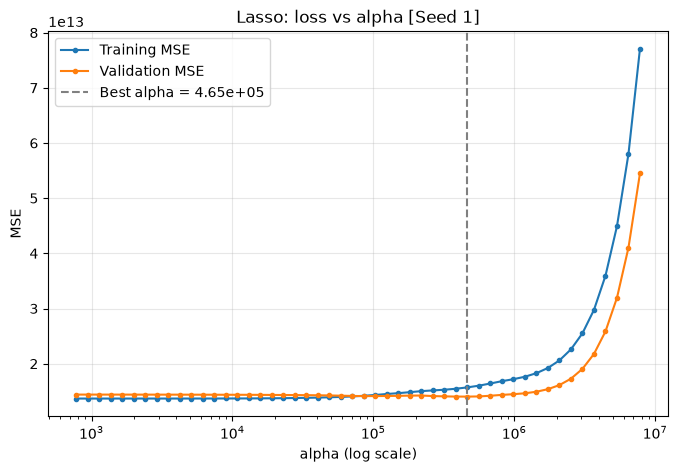

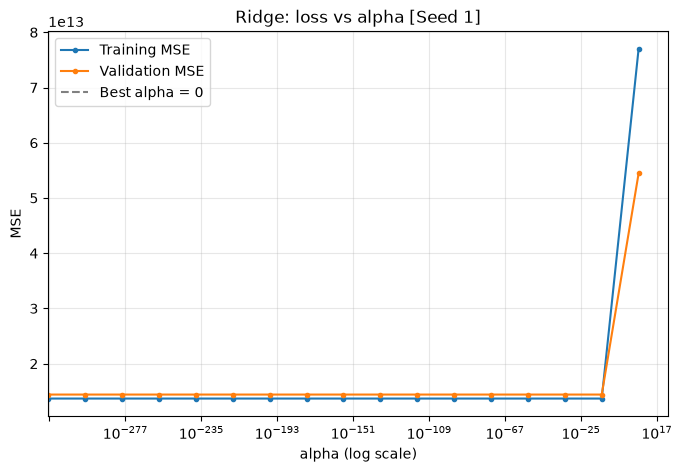

In [ ]:
# Here we rerun the data with a random seed, 140 instead of 42.
# The seed used when calling the functioning is for setting the initial alpha
X_seed1 = data_prep(df_clean, "Seed 1",seed=140)
res_clean = run_linreg(X_seed1, "Seed 1", df_clean.drop(columns=["Price"]).columns)
res_lasso, lasso_model, lasso_loss = run_lasso(
    X_seed1, "Seed 1",
    feature_names=df_clean.drop(columns=["Price"]).columns,
    seed=42,
)
res_ridge, ridge_model, ridge_loss = run_ridge(
    X_seed1, "Seed 1",
    feature_names=df_clean.drop(columns=["Price"]).columns,
    seed=42,
)

[Seed 2] split sizes: 1105 369 369
[Seed 2] constant and first 5 coefficients:
                          coef      std_err
const             1.038870e+07  117630.0561
Area              8.032527e+06  779035.7703
No. of Bedrooms  -7.900410e+05  301540.1109
Resale            8.120358e+05  180906.8852
MaintenanceStaff -3.357677e+05  138528.8732
Gymnasium        -5.819021e+05  309283.1659
[Seed 2] training R²:    0.8205
[Seed 2] validation MSE: 11340269688370.5742
[Seed 2] validation MAE: 2086097.2189
[Seed 2] validation R²:  0.8325

[Seed 2] random alpha: 2.815e+05 -> validation MSE: 11671971977023.8730
[Seed 2] best alpha:             3.345e+04
[Seed 2] non-zero coefficients:  32 of 38
[Seed 2] test MSE:               15647609425652.5117
[Seed 2] test MAE:               2335423.1933
[Seed 2] test R²:                0.7749

[Seed 2] non-zero coefficients (sorted by absolute size):
Area                   7.874990e+06
Resale                 7.394743e+05
No. of Bedrooms       -5.955405e+05
In

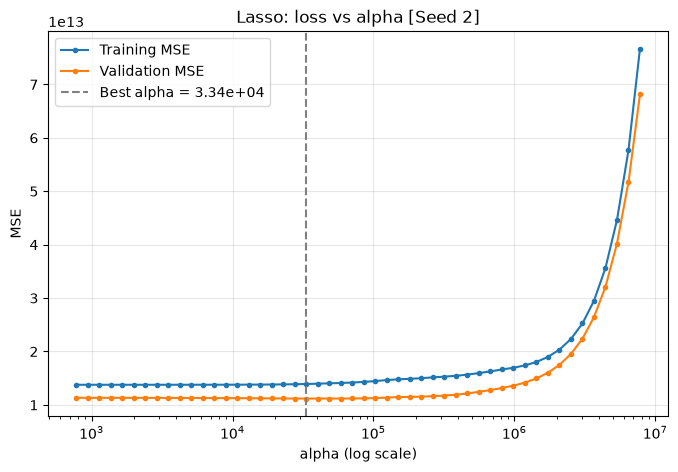

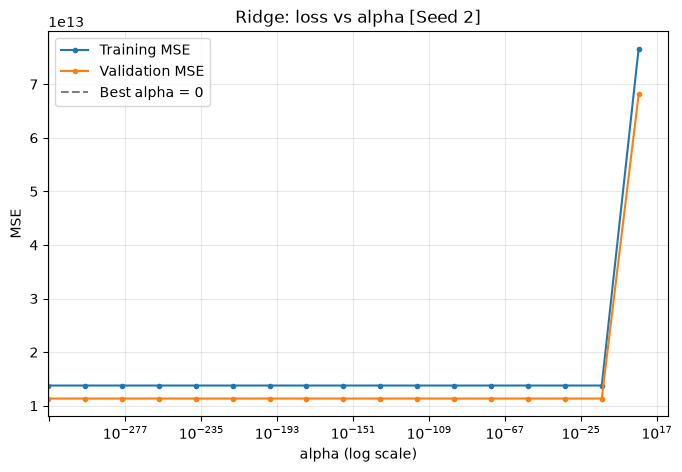

In [ ]:
#Second random seed 
X_seed2 = data_prep(df_clean, "Seed 2",seed=824)
res_clean = run_linreg(X_seed2, "Seed 2", df_clean.drop(columns=["Price"]).columns)
res_lasso, lasso_model, lasso_loss = run_lasso(X_seed2, "Seed 2",
    feature_names=df_clean.drop(columns=["Price"]).columns,
    seed=42,
)
res_ridge, ridge_model, ridge_loss = run_ridge( X_seed2, "Seed 2",
    feature_names=df_clean.drop(columns=["Price"]).columns,
    seed=42,
)


[unscaled] split sizes: 1105 369 369
[unscaled] constant and first 5 coefficients:
                          coef      std_err
const            -5.055646e+06  638499.6869
Area              1.104337e+04     557.7126
No. of Bedrooms  -1.617752e+06  409194.3939
Resale            1.260061e+06  344519.5425
MaintenanceStaff -1.137593e+06  476700.5768
Gymnasium        -1.100910e+06  682103.9461
[unscaled] training R²:    0.8218
[unscaled] validation MSE: 12130481031220.0508
[unscaled] validation MAE: 2194891.0070
[unscaled] validation R²:  0.8319

[Unscaled] random alpha: 6.691e+05 -> validation MSE: 14012490666009.0352
[Unscaled] best alpha:             3.825e+08
[Unscaled] non-zero coefficients:  1 of 38
[Unscaled] test MSE:               21185812977963.0625
[Unscaled] test MAE:               2559452.2967
[Unscaled] test R²:                0.7638

[Unscaled] non-zero coefficients (sorted by absolute size):
Area    9519.275317 

[Unscaled] random alpha: 0 -> validation MSE: 12130481031219.93

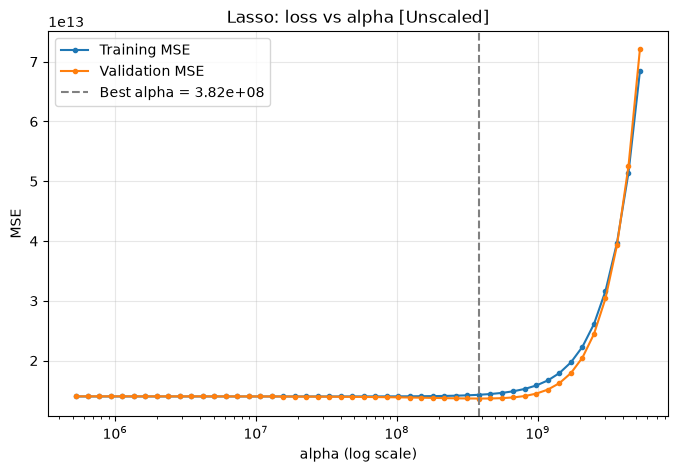

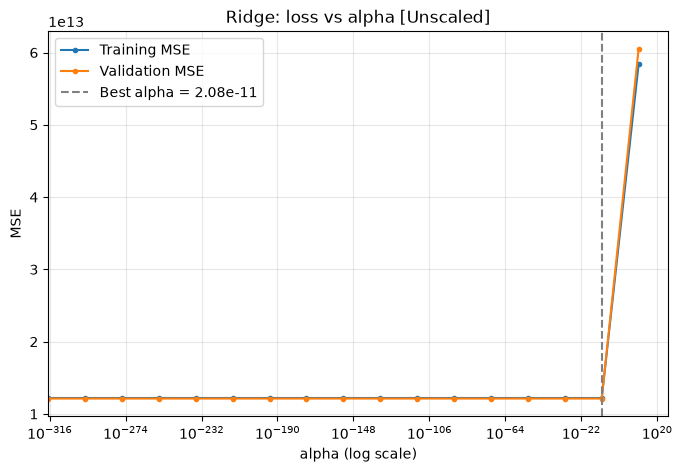

In [ ]:
#Now We set the sacling to false 
X_unscaled = data_prep(df_clean, "unscaled",seed=42,scale=False)
res_unscaled = run_linreg(X_unscaled, "unscaled", df_clean.drop(columns=["Price"]).columns)
res_lasso, lasso_model, lasso_loss = run_lasso(X_unscaled, "Unscaled",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)
res_ridge, ridge_model, ridge_loss = run_ridge( X_unscaled, "Unscaled",
    feature_names=df_clean.drop(columns=["Price"]).columns,
)


[df_clean] split sizes: 1105 369 369


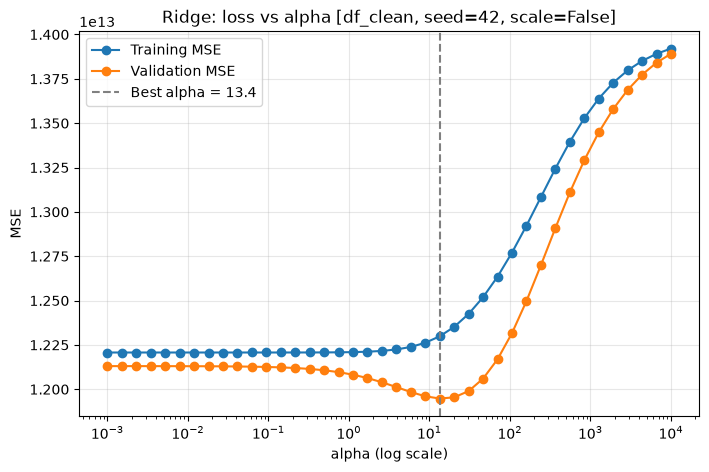

[df_clean] Ridge best alpha: 13.43
[df_clean] validation MSE: 11947523854200.3105
[df_clean] validation MAE: 2127928.0413
[df_clean] validation R²:  0.8344

[df_clean] split sizes: 1105 369 369


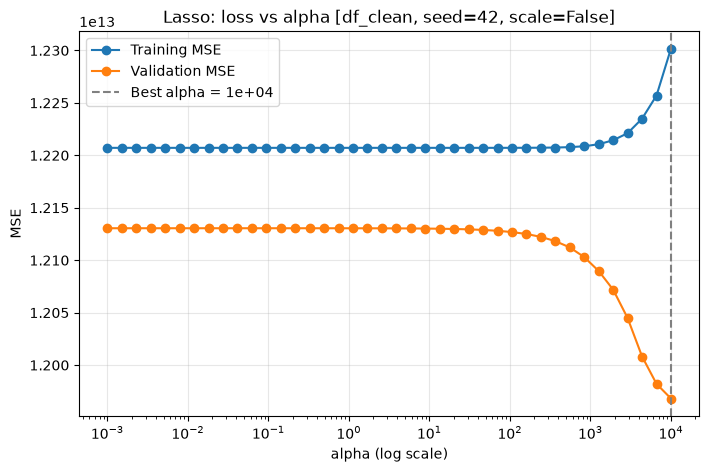

[df_clean] Lasso best alpha: 1e+04
[df_clean] validation MSE: 11968109212580.5469
[df_clean] validation MAE: 2134292.1378
[df_clean] validation R²:  0.8341

                                                       linreg         ridge  \
train_r2                                             0.820503           NaN   
val_mse                                 11340269688370.574219  1.194752e+13   
val_mae                                        2086097.218866  2.127928e+06   
val_r2                                               0.832501  8.343961e-01   
coef_table                            coef        std_err
...           NaN   
model                                      LinearRegression()           NaN   
alpha                                                     NaN  1.343399e+01   

                   lasso  
train_r2             NaN  
val_mse     1.196811e+13  
val_mae     2.134292e+06  
val_r2      8.341108e-01  
coef_table           NaN  
model                NaN  
alpha       1.000000e

In [ ]:
# def _tune_regularized(model_cls, data, label, seed, scale, alphas, **model_kwargs):
#     X_train, X_val, X_test, y_train, y_val, y_test = data_prep(
#         data, label, seed=seed, scale=scale
#     )

#     # Loop over the hyperparameter vector, fitting on the training data only
#     rows = []
#     for a in alphas:
#         model = model_cls(alpha=a, **model_kwargs).fit(X_train, y_train)
#         rows.append({
#             "alpha": a,
#             "train_mse": mean_squared_error(y_train, model.predict(X_train)),
#             "val_mse": mean_squared_error(y_val, model.predict(X_val)),
#         })
#     loss_df = pd.DataFrame(rows)

#     # Best alpha = lowest validation MSE
#     best_alpha = loss_df.loc[loss_df["val_mse"].idxmin(), "alpha"]

#     # Refit at the best alpha and collect validation metrics
#     best_model = model_cls(alpha=best_alpha, **model_kwargs).fit(X_train, y_train)
#     val_pred = best_model.predict(X_val)
#     results = {
#         "alpha": best_alpha,
#         "val_mse": mean_squared_error(y_val, val_pred),
#         "val_mae": mean_absolute_error(y_val, val_pred),
#         "val_r2": best_model.score(X_val, y_val),
#     }

#     # Plot loss against the hyperparameter
#     fig, ax = plt.subplots(figsize=(8, 5))
#     ax.plot(loss_df["alpha"], loss_df["train_mse"], marker="o", label="Training MSE")
#     ax.plot(loss_df["alpha"], loss_df["val_mse"], marker="o", label="Validation MSE")
#     ax.axvline(best_alpha, color="grey", linestyle="--", label=f"Best alpha = {best_alpha:.3g}")
#     ax.set_xscale("log")
#     ax.set_xlabel("alpha (log scale)")
#     ax.set_ylabel("MSE")
#     ax.set_title(f"{model_cls.__name__}: loss vs alpha [{label}, seed={seed}, scale={scale}]")
#     ax.legend()
#     ax.grid(True, alpha=0.3)
#     plt.show()

#     print(f"[{label}] {model_cls.__name__} best alpha: {best_alpha:.4g}")
#     print(f"[{label}] validation MSE: {results['val_mse']:.4f}")
#     print(f"[{label}] validation MAE: {results['val_mae']:.4f}")
#     print(f"[{label}] validation R²:  {results['val_r2']:.4f}\n")

#     return results, best_model, loss_df


# def run_ridge(data, label, seed=42, scale=True, alphas=np.logspace(-3, 4, 40)):
#     return _tune_regularized(Ridge, data, label, seed, scale, alphas)


# def run_lasso(data, label, seed=42, scale=True, alphas=np.logspace(-3, 4, 40)):
#     return _tune_regularized(Lasso, data, label, seed, scale, alphas, max_iter=20000)


# # Variables to check robustness 
# seed = 42
# scale = False

# # Model 1: linear regression on both dataframes
# # res_out   = run_linreg(prep_out,   "df_out")

# # Models 2 and 3: Ridge and Lasso on df_out only
# res_ridge, ridge_model, ridge_loss = run_ridge(df_out, "df_clean", seed=seed, scale=scale)
# res_lasso, lasso_model, lasso_loss = run_lasso(df_out, "df_clean", seed=seed, scale=scale)

# print(pd.DataFrame({"linreg": res_clean, "ridge": res_ridge, "lasso": res_lasso}))


In [159]:
def diebold_mariano(y_true, pred1, pred2, loss="squared", h=1, hln=True):
    y_true = np.asarray(y_true, dtype=float)
    e1 = y_true - np.asarray(pred1, dtype=float)
    e2 = y_true - np.asarray(pred2, dtype=float)

    d = (e1**2 - e2**2) if loss == "squared" else (np.abs(e1) - np.abs(e2))
    T = len(d)
    d_bar = d.mean()

    # Long-run variance of d (for h=1 this is just the plain variance)
    lrv = np.var(d, ddof=0)
    for k in range(1, h):
        lrv += 2 * np.cov(d[k:], d[:-k], ddof=0)[0, 1]

    dm = d_bar / np.sqrt(lrv / T)

    if hln:  # Harvey-Leybourne-Newbold small-sample correction
        dm *= np.sqrt((T + 1 - 2*h + h*(h - 1)/T) / T)
        p = 2 * (1 - stats.t.cdf(abs(dm), df=T - 1))
    else:
        p = 2 * (1 - stats.norm.cdf(abs(dm)))

    return {"DM": dm, "p_value": p, "mean_loss_diff": d_bar, "n": T}


# Same seed and scale you used for the models
X_train, X_val, X_test, y_train, y_val, y_test = data_prep(df_out, "df_out", seed=seed, scale=scale)

ridge_pred = ridge_model.predict(X_test)
lasso_pred = lasso_model.predict(X_test)

dm_result = diebold_mariano(y_test, ridge_pred, lasso_pred, loss="squared")
print(dm_result)

[df_out] split sizes: 1105 369 369
{'DM': np.float64(-1.142490350851221), 'p_value': np.float64(0.253993025560836), 'mean_loss_diff': np.float64(-71570823693.40602), 'n': 369}


In [ ]:
# def rmse(model, X_, y_):
    # return np.sqrt(mean_squared_error(y_, model.predict(X_)

## Robustness Check

Test whether your results are robust with respect to the following two aspects

- Change the seed while creating your training/validation/testing set at least twice. What happens with your results?
- Given the original 60/20/20 rule, investigate the sensitiveness of rescaling your variables. That is what happens if you did NOT rescale the variables?

Regarding both aspects, create new tables (Table 4 an 5) with forecasting results (MSPE/MAPE) and associated Diebold Mariano tests results. 
Finally, provide a short recommendation which model you should use to model housing prices. **(max 60 words)**


In [ ]:
# for name, m in [('LinearRegression', linreg), ('Ridge', ridge), ('Lasso', lasso)]:
#     test_mse = mean_squared_error(y_test, m.predict(X_test_s))
#     test_mae = mean_absolute_error(y_test, m.predict(X_test_s))
#     print(f"{name:6s} Test MAE: {test_mae:.4f} Test MSE: {test_mse:.4f}   Test RMSE: {np.sqrt(test_mse):.4f}")

NameError: name 'ridge' is not defined

# Model Choice 

After observing the 3 models I would recommend using the Lasso model 